### TO DO:

In [ ]:
#TO DO - everything needed modifying is done here
#update to the semester if needed (check where the data is)
folder = "/Fall 2022/"

#TO DO: MODIFY T0 YOUR COUNTRY below -
#No need change elsewhere, unless stated otherwise
main_country = "Morocco"

#TO DO: MODIFY YOUR COMPARABLE COUNTRIES HERE - MD
#make sure to include your main country (you modified already above)
comparable_countries = [main_country, 'South Africa', 'Rwanda', 'Tunisia']

#### Import Packages

In [ ]:
from google.colab import files
import io
import os
from tqdm import tqdm
import csv
!pip install xlwt
import xlwt

import statsmodels.api as sm
import statsmodels.formula.api as smf
import math
from sklearn.linear_model import LinearRegression

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd
from scipy import linalg as LA
import operator
from xlwt import Workbook
import xlwt

import plotly.express as px

import plotly.graph_objects as go
from plotly.subplots import make_subplots

zzz=np.random.randint(1,100)

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [ ]:
from google.colab import drive
drive.mount('/content/drive/', force_remount=True)

Mounted at /content/drive/


# Import Data

In [ ]:
##UPDATED - MD. Make sure you copy the folder to your personal drive

#'drive/My Drive/ECI Research/Fall 2022/Data/'
root_path = 'drive/My Drive/ECI Research/' +folder +'/Data/'

# Read input - CHECK DATA FOR RELEVANCE
#uploaded = files.upload()
df = pd.read_csv(root_path+'2019-2021 cleaned/2019clean.csv')
df1_cl= pd.read_csv(root_path+'2019-2021 cleaned/2019clean.csv', index_col=0)
#uploaded = files.upload()
df2 = pd.read_csv(root_path+'2019-2021 cleaned/2020clean.csv')
df2_cl= pd.read_csv(root_path+'2019-2021 cleaned/2020clean.csv', index_col=0)

df3 = pd.read_csv(root_path+'2019-2021 cleaned/2021clean.csv')
df3_cl= pd.read_csv(root_path+'2019-2021 cleaned/2021clean.csv', index_col=0)

df7 = pd.read_csv(root_path+'GDP4.csv')
df7 = df7.drop(columns = ['Country Code', 'Series Name'])
df7 = df7.dropna()
#df7_cl = pd.read_csv(root_path+'GDP4.csv', index_col=0)

#df7 = df7.drop(columns = ['Country Code', 'Indicator Name'])
#df7_cl = df7_cl.drop(columns = ['Country Code', 'Indicator Name'])



In [ ]:
def df_to_matrix(dfa):
  raw_matrixa = dfa.to_numpy()
  matrixa = [list(dfa.columns)]

  for row in raw_matrixa:

    stripped=np.char.strip(np.array(row[1::]).astype(str),chars='_')
    if np.min(stripped.astype(float)) > 0:
      matrixa.append(list(row))

  return matrixa

In [ ]:
## UPDATED - MD: needed to deal with non-numeric str and NAN for df7 (GDP4 file)
# equivalent to df_to_matrix(dfa)

def df7_to_matrix(df7_cl):
    temp = df7_cl.dropna()

    # Create an empty dictionary
    gdp_19to21_dict = {}

    # Iterate over the rows of the data frame
    for index, row in temp.iterrows():
      # Get the country name
      country = row['Country Name']

      # Get the values for 2019, 2020, and 2021
      value_2019 = row['2019']
      value_2019 = str(value_2019) #convert to str to test if isnumeric()
      value_2020 = row['2020']
      value_2020 = str(value_2020)
      value_2021 = row['2021']
      value_2021 = str(value_2021)

        # Check if the string contains only numeric characters
      if value_2019.isnumeric():
        value_2019 = float(value_2019)
      else:
      # Remove any non-numeric characters from the string
        value_2019 = None

      if value_2020.isnumeric():
        value_2020 = float(value_2020)
      else:
        value_2020 = None

      if value_2021.isnumeric():
        value_2021 = float(value_2021)
      else:
        value_2021 = None


      # Add a new entry to the dictionary with the country as the key
      # and the values for 2019, 2020, and 2021 as the values
      gdp_19to21_dict[country] = [(2019, value_2019), (2020, value_2020), (2021, value_2021)]

    # The output dictionary should now have an entry for each country in the data frame
    return gdp_19to21_dict

In [ ]:
#UPDATED
matrix = df_to_matrix(df) #for 2019
matrix2 = df_to_matrix(df2) #for 2020
matrix3 = df_to_matrix(df3) #for 2021

## Clean matrix
# for GDP up to 2021 including
matrix7 = df7_to_matrix(df7) #for GDP up to 2021 including
gdp_19to21_dict = matrix7

# ECI & PCI

MCP

In [ ]:
#compute mcp

def compute_mcp(matrix):
  product_list = matrix[0][1::]
  country_list = []
  for i in range(1,len(matrix)):
    country_list.append(matrix[i][0])

  country_sum = []
  for i in range(1,len(matrix)):
    stripped=np.char.strip(np.array(matrix[i][1::]).astype(str),chars='_')
    country_sum.append(np.sum(stripped.astype(float)))

  product_sum = []
  for i in range(1,len(matrix[0])):
    product = 0
    for j in range(1,len(matrix)):
        product += matrix[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)

  mcp = []

  for i in range (1,len(matrix)):
    country_row = []
    for j in range(1,len(matrix[i])):
      try:
        percentage = matrix[i][j]/country_sum[i-1]
      except:
        print(country_list[i-1])
      total_percentage = product_sum[j-1]/total_sum
      if percentage > total_percentage:
        country_row.append(1)
      else:
        country_row.append(0)
    mcp.append(country_row)

  return country_list,product_list,mcp,product_sum,country_sum

MCC

In [ ]:
#compute mcc
def compute_mcc(mcp):
  mcp2 = mcp
  country_sum = []
  for i in range(0,len(mcp)):
    country_sum.append(np.sum(mcp[i]))

  product_sum = []
  for i in range(0,len(mcp[0])):
    product = 0
    for j in range(0,len(mcp)):
      product += mcp[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)

  mcc = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp)):
      temp_sum = 0
      for k in range(0,len(mcp[0])):
        try:
          value = (mcp[i][k] * mcp2[j][k]/(country_sum[i]*product_sum[k]))
          if np.isinf(value) or np.isnan(value):
            temp_sum += 0
          else:
            temp_sum += value
        except:
          pass
      country_row.append(temp_sum)
    mcc.append(country_row)
  return mcc

MPP

In [ ]:
# compute mpp
def compute_mpp(mcp):
  mcp2 = mcp
  country_sum = []
  for i in range(0,len(mcp)):
    country_sum.append(np.sum(mcp[i]))

  product_sum = []
  for i in range(0,len(mcp[0])):
    product = 0
    for j in range(0,len(mcp)):
      product += mcp[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)

  mpp = []
  for i in range(0,len(mcp[0])):
    product_row = []
    for j in range(0,len(mcp[0])):
      temp_sum = 0
      for k in range(0,len(mcp)):
        try:
          temp_sum += (mcp[k][i] * mcp2[k][j]/(country_sum[k]*product_sum[i]))
        except:
          pass
      product_row.append(temp_sum)
    mpp.append(product_row)
  return mpp

ECI

In [ ]:
#compute ECI
def compute_eci(mcc):
  mcc = np.array(mcc)

  e_vals, e_vecs = LA.eig(mcc)
  eigenvectors = e_vecs.tolist()
  eigen = []
  for eigenvector in eigenvectors:
    temp = []
    for col in eigenvector:
      temp.append(col.real)
    eigen.append(temp)

  vector = []
  for i in range(0,len(eigen)):
    vector.append(eigen[i][1])

  eci = []
  if vector[0] < 0:
    for item in vector:
      eci.append((item-np.mean(vector))/np.std(vector))
  else:
    for item in vector:
      eci.append((-item+np.mean(vector))/np.std(vector))
  return eci

PCI

In [ ]:
#compute PCI
def compute_pci(mpp):
  mpp = np.array(mpp)
  e_vals, e_vecs = LA.eig(mpp)
  eigenvectors = e_vecs.tolist()
  eigen = []
  for eigenvector in eigenvectors:
    temp = []
    for col in eigenvector:
      temp.append(col.real)
    eigen.append(temp)

  vector = []
  for i in range(0,len(eigen)):
    vector.append(eigen[i][1])

  pci = []
  if vector[len(vector)-2] > 0:
    for item in vector:
      pci.append((item-np.mean(vector))/np.std(vector))
  else:
    for item in vector:
      pci.append((-item+np.mean(vector))/np.std(vector))
  return pci

In [ ]:
## ___18 is equivalent year 2021, will be used later
#matrix is for year 2019
#matrix2 is for year 2020
#FOR THIS UPDATE ONLY USE YEAR 2021 (matrix3)
country_list,product_list,mcp,product_sum,country_sum = compute_mcp(matrix3)
country_list_18,product_list_18,mcp_18,product_sum_18,country_sum_18 = compute_mcp(matrix3)

mcc = compute_mcc(mcp)
mpp = compute_mpp(mcp)

mcc_18 = compute_mcc(mcp_18)
mpp_18 = compute_mpp(mcp_18)

eci = compute_eci(mcc)
pci = compute_pci(mpp)

eci_18 = compute_eci(mcc_18)
pci_18 = compute_pci(mpp_18)

#check ECI
eci_dict = {}
for i in range(len(country_list)):
  eci_dict[country_list[i]]=eci[i]
sorted_eci_dict = sorted(eci_dict.items(), key=operator.itemgetter(1))

#check PCI
pci_dict = {}
for i in range(len(product_list)):
  pci_dict[product_list[i]]=pci[i]
sorted_pci_dict = sorted(pci_dict.items(), key=operator.itemgetter(1))

#check ECI
eci_dict_18 = {}
for i in range(len(country_list_18)):
  eci_dict_18[country_list_18[i]]=eci_18[i]
sorted_eci_dict_18 = sorted(eci_dict_18.items(), key=operator.itemgetter(1))

print(sorted_eci_dict)
#for item in sorted_pci_dict:
 # print(item)

[('Germany', -1.8612823629690707), ('Slovakia', -1.771917132991352), ('Hungary', -1.753063429361973), ('Japan', -1.747870967061478), ('Mexico', -1.6929989259542744), ('Czechia', -1.676602221024343), ('Other Asia, not elsewhere specified', -1.6323629102238444), ('Republic of Korea', -1.5471405836092913), ('Bermuda', -1.5198493127728747), ('Ireland', -1.5073565067844779), ('Slovenia', -1.3546625814110775), ('EU-28', -1.3504244000167172), ('Finland', -1.333972129918653), ('China', -1.3254003339146072), ('Switzerland, Liechtenstein', -1.3067892732336968), ('Malta', -1.2278438352538352), ('Cayman Islands', -1.1673281627854786), ('Singapore', -1.1299207842044807), ('Bosnia Herzegovina', -1.0462058275525519), ('Italy', -1.0363404900950133), ('Austria', -1.0094132304989116), ('Israel', -0.9044829164165856), ('United Kingdom', -0.8918050659580429), ('Netherlands', -0.8667523004878882), ('Tunisia', -0.8625434335286257), ('Denmark', -0.830338517428913), ('China, Hong Kong Special Administrative R

# Section 2 Graphs (ECI and GDP)

In [ ]:
#old to do, ignore

In [ ]:
##Changing matrices into dictionary format
def get_eci_dict(mat):
  country_list,product_list,mcp,product_sum,country_sum = compute_mcp(mat)
  mcc = compute_mcc(mcp)
  eci = compute_eci(mcc)
  eci_dict = {}
  for i in range(len(country_list)):
    eci_dict[country_list[i]]=eci[i]
  sorted_eci_dict = sorted(eci_dict.items(), key=operator.itemgetter(1))
  return sorted_eci_dict

In [ ]:
## Changing matrices into dictionary format
# matrix3 is for 2021
matrix3 = df_to_matrix(df3)
print(matrix3[3])
matrix3[18][3] = matrix3[18][3] *1

eci_2019 = get_eci_dict(matrix)
eci_2020 = get_eci_dict(matrix2)
eci_2021 = get_eci_dict(matrix3)

['Argentina', 6133264495.0, 13939853237.0, 18926694310.0, 2125622384.0, 155238272.0, 3030402788.0, 672770138.0, 310886137.0, 17616691.0, 325932038.0, 133211662.0, 14411066.0, 4697156871.0, 20921.0, 51136430.0, 728604305.0, 33775710701.0, 25793613594.0]


In [ ]:
from collections import defaultdict
eci_list = [eci_2019, eci_2020, eci_2021]
eci_19to21_dict = defaultdict(list)
i = 0
for li in eci_list:
  for entry in li:
    eci_19to21_dict[entry[0]].append((2019+i, entry[1]))
  i += 1

#this is a test for your country (you modified above)
eci_19to21_dict[main_country]


[]

In [ ]:
gdp_19to21_dict[main_country]

[(2019, 119870439114.0), (2020, 114725065285.0), (2021, 132725261467.0)]

Average Annual Growth Rate

In [ ]:
def aagrate(nums):
  tot = 0
  i = 0
  while i < len(nums) - 1:
    tot += (((nums[i+1]-nums[i])/nums[i]) * 100)
    i += 1
  return tot/len(nums)

GDP Peer Comparison Graph

In [ ]:
##pick comparable countries (modified in cell below) - UPDATED MD
#Go to old country report from your country and use same peer countries UNLESS you believe they are not comparable anymore

def gdp_comparison_graph(cnames):
  fig, ax = plt.subplots()

  for country_name in cnames:
    if country_name == 'Plurinational State of Bolivia':
      label = 'Bolivia'
    elif country_name == 'Norway, Svalbard and Jan Mayen':
      label = 'Norway'
    elif country_name == 'Russian Federation':
      label = 'Russia'
    elif country_name == 'Korea, Rep.':
      label = 'South Korea'
    else:
      label = country_name

    x_values = [x[0] for x in gdp_19to21_dict[country_name]]
    y_values = [float(x[1])/(10**9) for x in gdp_19to21_dict[country_name]]
    # Create the plot
    ax.plot(x_values, y_values, label = label)

    # Set the tick labels to custom values, '' added for consistent labeling
    ax.set_xticklabels(['', '2019', '', '', '', '2020', '', '',  '', '2021', ''])

  plt.ylabel('GDP in USD (billions)')
  plt.legend()
  plt.title('GDP Comparison Among Peer Countries')

  # Show the plot
  plt.show()
  plt.savefig('GDP Comparison for ' + country_name + '.png')

In [ ]:
#to deal with NA values
gdp_19to21_dict['United Arab Emirates'][2] = (2021, 415000000000)

<ipython-input-87-b4ffc8263614>:25: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(['', '2019', '', '', '', '2020', '', '',  '', '2021', ''])


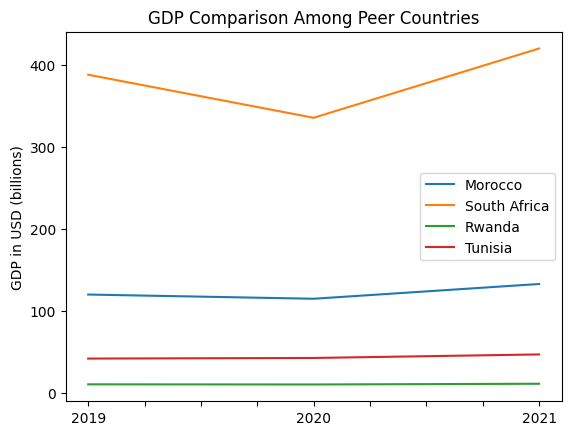

<Figure size 640x480 with 0 Axes>

In [ ]:
gdp_comparison_graph(comparable_countries)

In [ ]:
def printgdps(cns):
  for cn in cns:
    print(cn)
    print(round(aagrate([x[1] for x in gdp_19to21_dict[cn]]),2))

printgdps(comparable_countries)

Morocco
3.8
South Africa
3.89
Rwanda
2.35
Tunisia
3.98


ECI Peer Comparison Graph

In [ ]:
## UPDATED - MD
def eci_comparison_graph(cnames):
  fig, ax = plt.subplots()

  #cleanup country names
  for country_name in cnames:
    if country_name == 'Plurinational State of Bolivia':
      label = 'Bolivia'
    elif country_name == 'Norway, Svalbard and Jan Mayen':
      label = 'Norway'
    elif country_name == 'Russian Federation':
      label = 'Russia'
    elif country_name == 'France':
      country_name = 'France, Monaco'
      label = 'France'
    else:
      label = country_name

    x_values = [int(x[0]) for x in eci_19to21_dict[country_name]]
    y_values = [x[1] for x in eci_19to21_dict[country_name]]

    # Create the plot
    ax.plot(x_values, y_values, label = label)

    # Set the tick labels to custom values, '' added for consistent labeling
    ax.set_xticklabels(['', '2019', '', '', '', '2020', '', '',  '', '2021', ''])
    #print(eci_19to21_dict[country_name])

  plt.ylabel('ECI')
  plt.legend()
  plt.title('ECI Comparison Among Peer Countries')
  plt.show()
  plt.savefig('ECI Comparison for ' + country_name + '.png')

<ipython-input-105-b430b32b9ee6>:26: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(['', '2019', '', '', '', '2020', '', '',  '', '2021', ''])


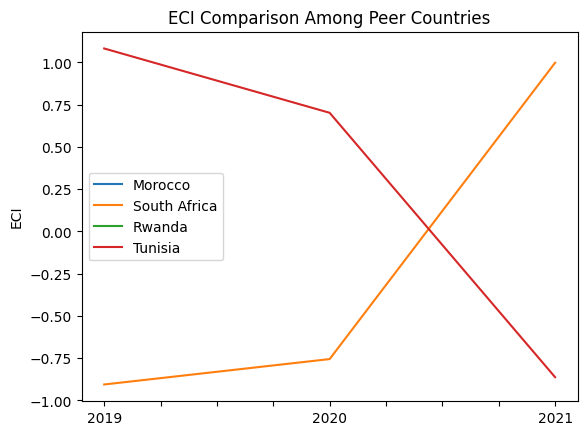

<Figure size 640x480 with 0 Axes>

In [ ]:
eci_comparison_graph(comparable_countries)

In [ ]:
## UPDATED - MD:
def eci_change(cns):
  for country_name in cns:
    if country_name == 'France':
      country_name = 'France, Monaco'
    elif country_name == "Korea, Rep.":
      country_name = 'Republic of Korea'
    #mytesting
    print(country_name)
    print(eci_19to21_dict[country_name])
    print(len(eci_19to21_dict[country_name])-1)
    print(eci_19to21_dict[country_name][0][1])

    print([1]-eci_19to21_dict[country_name][0][1])

    #official code
    print(round((eci_19to21_dict[country_name][len(eci_19to21_dict[country_name])-1][1]-eci_19to21_dict[country_name][0][1])/abs(eci_19to21_dict[country_name][0][1]) * 100,2))

eci_change(comparable_countries)

Morocco
[]
-1


IndexError: ignored

GDP Growth and ECI Trend Graph

In [ ]:
## ## UPDATED - MD:
def gdp_and_eci_graph(country_name):
  if country_name=='Vietnam': #not sure if some other names should be changed too
    country_name='Viet Nam'
  elif country_name == 'France':
    country_name = 'France, Monaco'

  fig, ax1 = plt.subplots()

  ax1.set_ylabel('GDP in USD (billions)')
  x_values = [x[0] for x in gdp_19to21_dict[country_name]]
  y_values = [float(x[1])/(10**9) for x in gdp_19to21_dict[country_name]]
    # Create the plot
  ax1.plot(x_values, y_values, color = 'red', label='GDP')

  # Set the tick labels to custom values, '' added for consistent labeling
  ax1.set_xticklabels(['', '2019', '', '', '', '2020', '', '',  '', '2021', ''])
  ax1.legend(loc = 'upper left')

  ax2 = ax1.twinx()
  ax2.set_ylabel('ECI')
  ax2.plot(x_values,[x[1] for x in eci_19to21_dict[country_name]], color = 'blue', label='ECI')
  ax2.legend(loc = 'upper right')
  plt.title('GDP and ECI Trend for ' + country_name)
  plt.show()
  plt.savefig('GDP and ECI Trend for ' + country_name + '.png')

<ipython-input-94-1dc19e16dbe5>:17: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax1.set_xticklabels(['', '2019', '', '', '', '2020', '', '',  '', '2021', ''])


ValueError: ignored

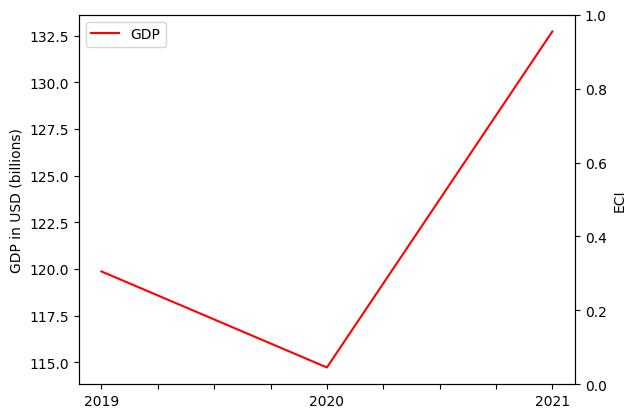

In [ ]:
gdp_and_eci_graph(main_country)

# Proximity, Distance, and RID

Proximity

In [ ]:
def compute_proximity(mcp,product_sum):
  proximity = []
  for i in range(0,len(mcp[0])):
    product_row = []
    for j in range(0,len(mcp[0])):
      temp_sum = 0
      for k in range(0,len(mcp)):
        try:
          temp_sum += mcp[k][i] * mcp[k][j]
        except:
          pass
      p0 = product_sum[i]
      p1 = product_sum[j]
      if p0 < p1:
        large = p1
      else:
        large = p0
      product_row.append(temp_sum/large)
    proximity.append(product_row)
  return proximity

Distance

In [ ]:
#compute distance
def compute_distance(mcp,proximity):
  distance = []
  for i in range(0,len(mcp)):
    product_row = []
    for j in range(0,len(mcp[0])):
      sum1 = 0
      for k in range(0,len(mcp[0])):
        if k != j:
          try:
            sum1 += mcp[i][k]*proximity[j][k]
          except:
            pass
      sum2 = 0
      for k in range(0,len(mcp[0])):
        if k != j:
          try:
            sum2 += proximity[j][k]
          except:
            pass
      product_row.append(1-sum1/sum2)
    distance.append(product_row)
  return distance

RID

In [ ]:
def compute_adi(df2,country_list,distance):
  raw_matrix = df2.to_numpy()
  matrix = [list(df2.columns)]
  for row in raw_matrix:
    if sum(row[1::]) > 0:
      matrix.append(list(row))

  country_list2,product_list2,mcp2,product_sum2,country_sum2 = compute_mcp(matrix)
  proximity2 = compute_proximity(mcp2,product_sum2)
  distance2 = compute_distance(mcp2,proximity2)

  adi = {}
  for i in range(len(country_list)):
    for j in range(len(country_list2)):
      if country_list[i] == country_list2[j]:
        adi[country_list[i]] = np.array(distance2[j]) - np.array(distance[i])
  return adi, country_list2,product_list2

In [ ]:
# 18 is equivalent to year 2021
proximity = compute_proximity(mcp,product_sum)
proximity_18 = compute_proximity(mcp_18,product_sum_18)

distance = compute_distance(mcp,proximity)
adi, country_list2,product_list2  = compute_adi(df2,country_list,distance)

In [ ]:
print(adi)

{'China': array([-0.00610023, -0.00626736,  0.0111762 , -0.01191056,  0.08354037,
        0.01800228,  0.0565964 ,  0.00589653,  0.02321423,  0.03203955,
        0.03274147,  0.02708753,  0.07009967,  0.03492262,  0.0764603 ,
       -0.01604462, -0.02798434, -0.00857523]), 'Angola': array([-0.03526822, -0.0225943 , -0.03178321, -0.00926201, -0.02505552,
       -0.01779039, -0.02372178, -0.028536  , -0.04055799, -0.03459257,
       -0.02974015, -0.00893082, -0.03753946, -0.01892008, -0.05381465,
       -0.01529726, -0.00890411, -0.03018067]), 'Argentina': array([ 0.01858347,  0.02440357,  0.01586534,  0.01946683, -0.03932879,
        0.02370625, -0.02563112,  0.03007493,  0.01325394, -0.01946807,
        0.00859965, -0.01114636,  0.02557574,  0.00604231, -0.0371431 ,
        0.03858787,  0.03023483,  0.0410265 ]), 'Armenia': array([-0.02651522, -0.00834849, -0.02182146,  0.01990259, -0.08555334,
       -0.06424669, -0.04428393, -0.00580573, -0.02021936, -0.05560809,
       -0.02352623, 

In [ ]:
# UPDATED
df_ = pd.DataFrame()
df_['Category'] = product_list_18
df_['RID'] = adi[main_country]
df_.sort_values(by="RID")

KeyError: ignored

In [ ]:
#peer countries TO DO optional:

df_comp = pd.DataFrame()
df_comp['Category'] = product_list_18
country_list = ['France, Monaco', 'USA, Puerto Rico and US Virgin Islands', 'Germany']
for count in country_list:
  df_comp[count + ' RID'] = adi[count]

df_comp.sort_values(by = 'France, Monaco' + ' RID')

,Category,"France, Monaco RID","USA, Puerto Rico and US Virgin Islands RID",Germany RID
9,Textile,-0.051994,-0.129064,0.080781
6,Raw Manufacturing,-0.023252,-0.096495,0.031618
14,Daily Instruments,-0.017109,-0.051863,0.148134
4,Chemicals,-0.011985,-0.104290,0.114220
12,Transportation,-0.005112,-0.134026,0.127016
7,Wood Products,0.003416,-0.044495,0.036345
13,Weapons,0.004409,-0.111668,0.076944
10,Metals,0.007862,-0.110494,0.079607
8,Clothing and Accessories,0.010170,-0.099894,0.083047
0,Animals and By-products,0.011525,-0.118577,0.059777


In [ ]:
#peer countries TO DO optional:

df_comp = pd.DataFrame()
df_comp['Category'] = product_list_18
country_list = ['China', 'Republic of Korea', 'Singapore']
for count in country_list:
  df_comp[count + ' RID'] = adi[count]

df_comp

,Category,China RID,Republic of Korea RID,Singapore RID
0,Animals and By-products,-0.006100,-0.018783,-0.045522
1,"Vegetables, Fruits and Plants",-0.006267,-0.020537,-0.036958
2,Food and Preparations,0.011176,-0.007043,-0.052897
3,Energy Drilling and Mining,-0.011911,-0.008470,0.000067
4,Chemicals,0.083540,0.063172,-0.045287
5,Chemical Manufacturing,0.018002,0.022953,-0.012957
6,Raw Manufacturing,0.056596,0.030634,-0.015463
7,Wood Products,0.005897,0.001072,-0.041264
8,Clothing and Accessories,0.023214,0.010085,-0.058307
9,Textile,0.032040,0.032065,-0.015065


In [ ]:
# UPDATED - for multiple countries
df_comp = pd.DataFrame()
df_comp['Category'] = product_list_18
country_list = [main_country, 'India', 'Greece']
for count in country_list:
  df_comp[count + ' RID'] = adi[count]
  print(count)
  print(eci_19to21_dict[count])

df_comp.sort_values(by = main_country + ' RID')

Italy
[(2019, 1.2314198507071683), (2020, 1.0218876193526367), (2021, -1.0363404900950133)]
India
[(2019, -0.43661858195006564), (2020, -0.2099386993439353), (2021, 0.40764646781003905)]
Greece
[(2019, -0.2204101210137976), (2020, -0.13309105880045025), (2021, 0.23035793848767286)]


,Category,Italy RID,India RID,Greece RID
15,Precious Stones\t,-0.006769,-0.018396,-0.019082
0,Animals and By-products,0.007625,-0.027877,-0.019800
1,"Vegetables, Fruits and Plants",0.008200,-0.024656,-0.011328
11,Machinery and Construction,0.009494,-0.031650,-0.038720
17,Services and Utilities,0.010730,0.003788,0.002698
3,Energy Drilling and Mining,0.026295,0.016021,0.013123
14,Daily Instruments,0.027065,-0.014820,-0.042296
2,Food and Preparations,0.033415,-0.029354,-0.016354
13,Weapons,0.035583,-0.060457,-0.019627
8,Clothing and Accessories,0.042580,-0.031514,0.008191


In [ ]:
# UPDATED - for multiple countries
df_comp = pd.DataFrame()
df_comp['Category'] = product_list_18
country_list_temp = [ 'Italy', 'Spain', 'United Arab Emirates']
for count in country_list_temp:
  df_comp[count + ' RID'] = adi[count]
  print(count)
  print(eci_19to21_dict[count])

df_comp

Italy
[(2019, 1.2314198507071683), (2020, 1.0218876193526367), (2021, -1.0363404900950133)]
Spain
[(2019, 0.6180212207508369), (2020, 0.7620140512194398), (2021, -0.5616917471435152)]
United Arab Emirates
[(2019, -2.0786463574833), (2020, -1.928217301763961), (2021, 2.231673373922602)]


,Category,Italy RID,Spain RID,United Arab Emirates RID
0,Animals and By-products,0.007625,0.014024,-0.035268
1,"Vegetables, Fruits and Plants",0.008200,0.033408,-0.022594
2,Food and Preparations,0.033415,0.026281,-0.031783
3,Energy Drilling and Mining,0.026295,0.032765,-0.009262
4,Chemicals,0.093551,-0.023224,-0.025056
5,Chemical Manufacturing,0.050231,-0.006665,-0.017790
6,Raw Manufacturing,0.085149,0.002014,-0.023722
7,Wood Products,0.048162,0.030028,-0.028536
8,Clothing and Accessories,0.042580,0.022356,-0.040558
9,Textile,0.049851,0.010845,-0.034593


In [ ]:
df_comp

,Category,Italy RID,Spain RID,United Arab Emirates RID
0,Animals and By-products,0.007625,0.014024,-0.035268
1,"Vegetables, Fruits and Plants",0.008200,0.033408,-0.022594
2,Food and Preparations,0.033415,0.026281,-0.031783
3,Energy Drilling and Mining,0.026295,0.032765,-0.009262
4,Chemicals,0.093551,-0.023224,-0.025056
5,Chemical Manufacturing,0.050231,-0.006665,-0.017790
6,Raw Manufacturing,0.085149,0.002014,-0.023722
7,Wood Products,0.048162,0.030028,-0.028536
8,Clothing and Accessories,0.042580,0.022356,-0.040558
9,Textile,0.049851,0.010845,-0.034593


# Sequential Strategy

Opportunity Gain

In [ ]:
def compute_opportunity_gain(mcp,proximity,pci):
  opportunity_gain = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      gain = 0
      for k in range(0,len(mcp[0])):
        temp = 0
        for l in range(0,len(mcp[0])):
          temp += proximity[l][k]
        gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
      gain = gain - (1-distance[i][j]) * pci[j]
      if mcp[i][j] == 1:
        country_row.append(0)
      else:
        country_row.append(gain)
      #country_row.append(gain)
    opportunity_gain.append(country_row)

  opportunity_gain = np.array(opportunity_gain)
  return opportunity_gain

Marginal Opportunity Gain

In [ ]:
def compute_marginal_opportunity_gain(mcp,opportunity_gain,country_sum,product_sum,matrix):
  marginal = []
  total_sum = np.sum(product_sum)
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      if mcp[i][j] == 1:
        country_row.append(0)
      else:
        export = matrix[i+1][j+1]
        country_export = country_sum[i]
        product_export = product_sum[j]
        export_increase = (product_export*country_export/total_sum)-export
        country_row.append(opportunity_gain[i][j]*export/export_increase)
    marginal.append(country_row)

  marginal = np.array(marginal)
  return marginal

In [ ]:
opportunity_gain = compute_opportunity_gain(mcp,proximity,pci)
opportunity_gain_18 = compute_opportunity_gain(mcp_18,proximity_18,pci_18)

marginal_opportunity_gain = compute_marginal_opportunity_gain(mcp,opportunity_gain,country_sum,product_sum,matrix)

#for i in range(len(country_list)):
#  print(country_list[i],opportunity_gain[i])

In [ ]:
# For computation of sequential strategies, refer to sequential strategy.py

In [ ]:
# For sensitivity analysis, refer to sensitivity.ipynb

In [ ]:
# For computation of SOI, soi.ipynb

# SDV & SIDS

In [ ]:
def read_country(filename):
    f = open(filename,'r', encoding='utf-8')
    reader = csv.reader(f)
    raw_matrix = []
    for row in reader:
        temp = []
        for i in range(0,len(row)):
            try:
                temp.append(float(row[i]))
            except ValueError:
                temp.append(row[i])
        raw_matrix.append(temp)
    f.close()
    return raw_matrix

def rank(score_dict):
    rank_list = []
    score_list = []
    for item in score_dict:
        score_list.append(score_dict[item])
    while score_list:
        maximum = max(score_list)
        for item in score_dict:
            if score_dict[item] == maximum:
                rank_list.append(item)
        score_list = [score for score in score_list if score!= maximum]
    return rank_list


def sdv_and_sids(country, year):
    #Read the raw matrix
    raw_matrix = read_country(f"{year}.csv")
    raw_matrix = [row for row in raw_matrix if np.all(row[1:]==np.zeros(len(row)-1)) == False]
    raw_matrix[19][3] = raw_matrix[19][3]
    #compute mcp
    product_list = raw_matrix[0][1::]
    country_list = []
    for i in range(1,len(raw_matrix)):
        country_list.append(raw_matrix[i][0])

    country_sum = []
    for i in range(1,len(raw_matrix)):
        country_sum.append(np.sum(raw_matrix[i][1::]))

    product_sum = []
    for i in range(1,len(raw_matrix[0])):
        product = 0
        for j in range(1,len(raw_matrix)):
            product += raw_matrix[j][i]
        product_sum.append(product)
    total_sum = np.sum(product_sum)

    print(product_list)
    print(country_list)

    mcp = []

    for i in range (1,len(raw_matrix)):
        country_row = []
        for j in range(1,len(raw_matrix[i])):
            percentage = raw_matrix[i][j]/country_sum[i-1]
            total_percentage = product_sum[j-1]/total_sum
            if percentage > total_percentage:
                country_row.append(1)
            else:
                country_row.append(0)
        mcp.append(country_row)

    #compute mpp
    country_sum2 = []
    for i in range(0,len(mcp)):
        country_sum2.append(np.sum(mcp[i]))

    product_sum2 = []
    for i in range(0,len(mcp[0])):
        product = 0
        for j in range(0,len(mcp)):
            product += mcp[j][i]
        product_sum2.append(product)

    mpp = []
    for i in range(0,len(mcp[0])):
        product_row = []
        for j in range(0,len(mcp[0])):
            temp_sum = 0
            for k in range(0,len(mcp)):
                try:
                    temp_sum += (mcp[k][i] * mcp[k][j]/(country_sum2[k]*product_sum2[i]))
                except:
                    pass
            product_row.append(temp_sum)
        mpp.append(product_row)

    #compute PCI
    mpp = np.array(mpp)

    e_vals, e_vecs = LA.eig(mpp)
    eigenvectors = e_vecs.tolist()
    eigen = []
    for eigenvector in eigenvectors:
        temp = []
        for col in eigenvector:
            temp.append(col.real)
        eigen.append(temp)

    vector = []
    for i in range(0,len(eigen)):
        vector.append(eigen[i][1])

    pci = []
    if vector[len(vector)-2] > 0:
        for item in vector:
            pci.append((item-np.mean(vector))/np.std(vector))
    else:
        for item in vector:
            pci.append((-item+np.mean(vector))/np.std(vector))

    #compute proximity
    proximity = []
    for i in range(0,len(mcp[0])):
        product_row = []
        for j in range(0,len(mcp[0])):
            temp_sum = 0
            for k in range(0,len(mcp)):
                try:
                    temp_sum += mcp[k][i] * mcp[k][j]
                except:
                    pass
            p0 = product_sum2[i]
            p1 = product_sum2[j]
            if p0 < p1:
                large = p1
            else:
                large = p0
            product_row.append(temp_sum/large)
        proximity.append(product_row)

    #compute actual distance
    distance = []
    for i in range(0,len(mcp)):
        product_row = []
        for j in range(0,len(mcp[0])):
            sum1 = 0
            for k in range(0,len(mcp[0])):
                try:
                    sum1 += (1-mcp[i][k])*proximity[j][k]
                except:
                    pass
            sum2 = 0
            for k in range(0,len(mcp[0])):
                try:
                    sum2 += proximity[j][k]
                except:
                    pass
            if mcp[i][j] == 1:
                product_row.append(0)
            else:
                product_row.append(sum1/sum2)
        distance.append(product_row)

    #compute opportunity gain
    opportunity_gain = []
    for i in range(0,len(mcp)):
        country_row = []
        for j in range(0,len(mcp[0])):
            gain = 0
            for k in range(0,len(mcp[0])):
                temp = 0
                for l in range(0,len(mcp[0])):
                    temp += proximity[l][k]
                gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
            gain = gain - (1-distance[i][j]) * pci[j]
            if mcp[i][j] == 1:
                country_row.append(0)
            else:
                country_row.append(gain)
        opportunity_gain.append(country_row)

    #compute marginal opportunity gain
    marginal = []
    for i in range(0,len(mcp)):
        country_row = []
        for j in range(0,len(mcp[0])):
            if mcp[i][j] == 1:
                country_row.append(0)
            else:
                export = raw_matrix[i+1][j+1]
                country_export = country_sum[i]
                product_export = product_sum[j]
                export_increase = (product_export*country_export/total_sum)-export
                country_row.append(opportunity_gain[i][j]*country_export/export_increase)
        marginal.append(country_row)


    #computing sequential strategy
    strategy = []

    for i in range(0,len(country_list)):
        if country in country_list[i]:
            country_index = i
    og = np.copy(opportunity_gain[country_index])
    sdv = dict(zip(product_list, og))
    sdv = sorted(sdv.items(), key=operator.itemgetter(1), reverse=True)
    sdv_colors = []
    for i in range(len(sdv)):
        if sdv[i][1]>0:
          sdv_colors.append(44)
        elif sdv[i][1]==0:
          sdv_colors.append(27)
        else:
          sdv_colors.append(1)
    print("Before Iteration: ")
    for i in range(0,len(marginal[country_index])):
        print(product_list[i], ": ", marginal[country_index][i])
    print(" ")

    temp = []
    temp.append("Before Iteration")
    posi = {}
    zero = []
    nega = {}
    colors = []
    color = [1]
    for i in range(0,len(marginal[country_index])):
        if marginal[country_index][i] > 0:
            posi[product_list[i]] = marginal[country_index][i]
        elif marginal[country_index][i] == 0:
            zero.append(product_list[i])
        else:
            nega[product_list[i]] = marginal[country_index][i]
    posi = rank(posi)
    nega = rank(nega)
    temp.extend(posi)
    color.extend([44 for i in range(len(posi))])
    temp.extend(zero)
    color.extend([27 for i in range(len(zero))])
    temp.extend(nega)
    color.extend([1 for i in range(len(nega))])
    strategy.append(temp)
    colors.append(color)

    ite_round = 0
    prev_industry = []

    while max(marginal[country_index]) > 0 and ite_round < 20:
        ite_round += 1

        value = max(marginal[country_index])
        for i in range(0,len(marginal[0])):
            if marginal[country_index][i] == value:
                industry_index = i
        industry = product_list[industry_index]
        prev_industry.append(industry_index)

        #calculate new export
        export = raw_matrix[country_index+1][industry_index+1]
        country_export = country_sum[country_index]
        product_export = product_sum[industry_index]
        required_export = product_export*country_export/total_sum
        export_increase = required_export-export

        print("increase ", industry, " in ", country, " by ", export_increase, " USD")

        raw_matrix[country_index+1][industry_index+1] = required_export*1.3

        #calculate everything again
        country_sum = []
        for i in range(1,len(raw_matrix)):
            country_sum.append(np.sum(raw_matrix[i][1::]))

        product_sum = []
        for i in range(1,len(raw_matrix[0])):
            product = 0
            for j in range(1,len(raw_matrix)):
                product += raw_matrix[j][i]
            product_sum.append(product)
        total_sum = np.sum(product_sum)

        mcp = []

        for i in range (1,len(raw_matrix)):
            country_row = []
            for j in range(1,len(raw_matrix[i])):
                percentage = raw_matrix[i][j]/country_sum[i-1]
                total_percentage = product_sum[j-1]/total_sum
                if percentage > total_percentage:
                    country_row.append(1)
                else:
                    country_row.append(0)
            mcp.append(country_row)

        #compute mpp
        country_sum2 = []
        for i in range(0,len(mcp)):
            country_sum2.append(np.sum(mcp[i]))

        product_sum2 = []
        for i in range(0,len(mcp[0])):
            product = 0
            for j in range(0,len(mcp)):
                product += mcp[j][i]
            product_sum2.append(product)

        mpp = []
        for i in range(0,len(mcp[0])):
            product_row = []
            for j in range(0,len(mcp[0])):
                temp_sum = 0
                for k in range(0,len(mcp)):
                    try:
                        temp_sum += (mcp[k][i] * mcp[k][j]/(country_sum2[k]*product_sum2[i]))
                    except:
                        pass
                product_row.append(temp_sum)
            mpp.append(product_row)

        #compute PCI
        mpp = np.array(mpp)

        e_vals, e_vecs = LA.eig(mpp)
        eigenvectors = e_vecs.tolist()
        eigen = []
        for eigenvector in eigenvectors:
            temp = []
            for col in eigenvector:
                temp.append(col.real)
            eigen.append(temp)

        vector = []
        for i in range(0,len(eigen)):
            vector.append(eigen[i][1])

        pci = []
        if vector[len(vector)-2] > 0:
            for item in vector:
                pci.append((item-np.mean(vector))/np.std(vector))
        else:
            for item in vector:
                pci.append((-item+np.mean(vector))/np.std(vector))

        #compute proximity
        proximity = []
        for i in range(0,len(mcp[0])):
            product_row = []
            for j in range(0,len(mcp[0])):
                temp_sum = 0
                for k in range(0,len(mcp)):
                    try:
                        temp_sum += mcp[k][i] * mcp[k][j]
                    except:
                        pass
                p0 = product_sum2[i]
                p1 = product_sum2[j]
                if p0 < p1:
                    large = p1
                else:
                    large = p0
                product_row.append(temp_sum/large)
            proximity.append(product_row)

        #compute actual distance
        distance = []
        for i in range(0,len(mcp)):
            product_row = []
            for j in range(0,len(mcp[0])):
                sum1 = 0
                for k in range(0,len(mcp[0])):
                    try:
                        sum1 += (1-mcp[i][k])*proximity[j][k]
                    except:
                        pass
                sum2 = 0
                for k in range(0,len(mcp[0])):
                    try:
                        sum2 += proximity[j][k]
                    except:
                        pass
                if mcp[i][j] == 1:
                    product_row.append(0)
                else:
                    product_row.append(sum1/sum2)
            distance.append(product_row)

        #compute opportunity gain
        opportunity_gain = []
        for i in range(0,len(mcp)):
            country_row = []
            for j in range(0,len(mcp[0])):
                gain = 0
                for k in range(0,len(mcp[0])):
                    temp = 0
                    for l in range(0,len(mcp[0])):
                        temp += proximity[l][k]
                    gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
                gain = gain - (1-distance[i][j]) * pci[j]
                if mcp[i][j] == 1:
                    country_row.append(0)
                else:
                    country_row.append(gain)
            opportunity_gain.append(country_row)

        #compute marginal opportunity gain
        marginal = []
        for i in range(0,len(mcp)):
            country_row = []
            for j in range(0,len(mcp[0])):
                if mcp[i][j] == 1:
                    country_row.append(0)
                else:
                    export = raw_matrix[i+1][j+1]
                    country_export = country_sum[i]
                    product_export = product_sum[j]
                    export_increase = (product_export*country_export/total_sum)-export
                    country_row.append(opportunity_gain[i][j]*country_export/export_increase)
            marginal.append(country_row)

        print("Iteration ", ite_round, ": ")
        for i in range(0,len(marginal[country_index])):
            print(product_list[i], ": ", marginal[country_index][i])
        print(" ")

        temp = []
        string = "Iteration " + str(ite_round)
        temp.append(string)
        posi = {}
        zero = []
        nega = {}
        color = [1]
        for i in range(0,len(marginal[country_index])):
            if marginal[country_index][i] > 0:
                posi[product_list[i]] = marginal[country_index][i]
            elif marginal[country_index][i] == 0:
                zero.append(product_list[i])
            else:
                nega[product_list[i]] = marginal[country_index][i]
        posi = rank(posi)
        nega = rank(nega)
        temp.extend(posi)
        color.extend([44 for i in range(len(posi))])
        temp.extend(zero)
        color.extend([27 for i in range(len(zero))])
        temp.extend(nega)
        color.extend([1 for i in range(len(nega))])
        strategy.append(temp)
        colors.append(color)

    strategy = np.array(strategy)
    strategy = np.transpose(strategy)
    colors = np.array(colors)
    colors = np.transpose(colors)
    #print(f'color shape is {colors.shape}')

    book = Workbook()
    sheet1 = book.add_sheet('Sheet 1')
    for i in range(0,len(strategy)):
        for j in range(len(strategy[0])):
          st = xlwt.easyxf('pattern: pattern solid;')
          st.pattern.pattern_fore_colour = colors[i][j]
          sheet1.write(i,j,strategy[i][j], st)
    book.save(f'sequential strategy of {country}.xls')

    book = Workbook()
    sheet1 = book.add_sheet('Sheet 1')
    for i in range(0,len(sdv)):
          st = xlwt.easyxf('pattern: pattern solid;')
          st.pattern.pattern_fore_colour = sdv_colors[i]
          sheet1.write(i, 0, sdv[i][0], st)
    book.save(f'sequential vector of {country}.xls')
    print(f'{country} completed')


## UPDATED - MD:  from here only
# TO DO: update "comparable_countries" below if needed
def main():
    countries = comparable_countries
    for country in countries:
      if country == 'France':
        country = 'France, Monaco'

      sdv_and_sids(country, root_path+'2019-2021 cleaned/2021clean')

In [ ]:
##OLD - ending of the code above
'''
def main():
    countries = ['Viet Nam','Lao People\'s Dem. Rep.','Cambodia', 'Thailand']

    for country in countries:
        sdv_and_sids(country, root_path+'2013-2018 cleaned/2018clean')
        '''

"\ndef main():\n    countries = ['Viet Nam','Lao People's Dem. Rep.','Cambodia', 'Thailand']\n\n    for country in countries:\n        sdv_and_sids(country, root_path+'2013-2018 cleaned/2018clean')\n        "

In [ ]:
if __name__ == "__main__":
    main()   #Optional: Change the countries and year above to have different results

<ipython-input-59-c62c7e801b79>:33: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  raw_matrix = [row for row in raw_matrix if np.all(row[1:]==np.zeros(len(row)-1)) == False]


['Animals and By-products', 'Vegetables, Fruits and Plants', 'Food and Preparations', 'Energy Drilling and Mining', 'Chemicals', 'Chemical Manufacturing', 'Raw Manufacturing', 'Wood Products', 'Clothing and Accessories', 'Textile', 'Metals', 'Machinery and Construction', 'Transportation', 'Weapons', 'Daily Instruments', 'Precious Stones\t', 'High-complexity Products', 'Services and Utilities']
['China', 'Angola', 'Argentina', 'Armenia', 'Aruba', 'Australia', 'Austria', 'Azerbaijan', 'Barbados', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bermuda', 'Plurinational State of Bolivia', 'Bosnia Herzegovina', 'Botswana', 'Brazil', 'Brunei Darussalam', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Canada', 'Cayman Islands', 'Chile', 'China, Hong Kong Special Administrative Region', 'China, Macao Special Administrative Region', 'Colombia', 'Comoros', 'Congo', 'Costa Rica', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Estonia', 'Ethiopi

In [ ]:
# UPDATED - SDV for multiple countries
df_comp = pd.DataFrame()
df_comp['Category'] = product_list_18
country_list_temp = [ 'Italy', 'Spain', 'United Arab Emirates']
for count in country_list_temp:
  df_comp[count + ' SDV'] = sdv_and_sids(count, root_path+'2019-2021 cleaned/2021clean')
  print(count)
  print(eci_19to21_dict[count])

df_comp

<ipython-input-59-c62c7e801b79>:33: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  raw_matrix = [row for row in raw_matrix if np.all(row[1:]==np.zeros(len(row)-1)) == False]


['Animals and By-products', 'Vegetables, Fruits and Plants', 'Food and Preparations', 'Energy Drilling and Mining', 'Chemicals', 'Chemical Manufacturing', 'Raw Manufacturing', 'Wood Products', 'Clothing and Accessories', 'Textile', 'Metals', 'Machinery and Construction', 'Transportation', 'Weapons', 'Daily Instruments', 'Precious Stones\t', 'High-complexity Products', 'Services and Utilities']
['China', 'Angola', 'Argentina', 'Armenia', 'Aruba', 'Australia', 'Austria', 'Azerbaijan', 'Barbados', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bermuda', 'Plurinational State of Bolivia', 'Bosnia Herzegovina', 'Botswana', 'Brazil', 'Brunei Darussalam', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Canada', 'Cayman Islands', 'Chile', 'China, Hong Kong Special Administrative Region', 'China, Macao Special Administrative Region', 'Colombia', 'Comoros', 'Congo', 'Costa Rica', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Estonia', 'Ethiopi

<ipython-input-59-c62c7e801b79>:33: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  raw_matrix = [row for row in raw_matrix if np.all(row[1:]==np.zeros(len(row)-1)) == False]


Iteration  1 : 
Animals and By-products :  0
Vegetables, Fruits and Plants :  0
Food and Preparations :  0
Energy Drilling and Mining :  11.849549285995321
Chemicals :  -19.210943296510127
Chemical Manufacturing :  0
Raw Manufacturing :  0
Wood Products :  0
Clothing and Accessories :  0
Textile :  102.00131841597724
Metals :  0
Machinery and Construction :  0
Transportation :  -7.008674708853622
Weapons :  635.547989306633
Daily Instruments :  -6.801303942933685
Precious Stones	 :  11.566997524676884
High-complexity Products :  0
Services and Utilities :  0
 
increase  Weapons  in  Spain  by  69481686.27150837  USD
Iteration  2 : 
Animals and By-products :  0
Vegetables, Fruits and Plants :  0
Food and Preparations :  0
Energy Drilling and Mining :  13.325488935761205
Chemicals :  -25.734889859618974
Chemical Manufacturing :  0
Raw Manufacturing :  0
Wood Products :  0
Clothing and Accessories :  0
Textile :  107.58241720212294
Metals :  0
Machinery and Construction :  0
Transportatio

<ipython-input-59-c62c7e801b79>:33: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  raw_matrix = [row for row in raw_matrix if np.all(row[1:]==np.zeros(len(row)-1)) == False]


Iteration  1 : 
Animals and By-products :  -9.046481630114497
Vegetables, Fruits and Plants :  -14.022116607340191
Food and Preparations :  -11.936470204999754
Energy Drilling and Mining :  0
Chemicals :  20.91676269482131
Chemical Manufacturing :  7.124464899498525
Raw Manufacturing :  8.840145398146309
Wood Products :  -1.7701006957447303
Clothing and Accessories :  -2.837255437626743
Textile :  0.7437154150923015
Metals :  0.8512853758993432
Machinery and Construction :  161.78740248067737
Transportation :  6.0768560102646285
Weapons :  0
Daily Instruments :  8.728744211173002
Precious Stones	 :  0
High-complexity Products :  3.0923673097062854
Services and Utilities :  14.003689280079408
 
increase  Machinery and Construction  in  United Arab Emirates  by  891740611.7625477  USD
Iteration  2 : 
Animals and By-products :  -9.227444805588455
Vegetables, Fruits and Plants :  -14.302537116253214
Food and Preparations :  -12.435853720184749
Energy Drilling and Mining :  0
Chemicals :  1

,Category,Italy SDV,Spain SDV,United Arab Emirates SDV
0,Animals and By-products,None,None,None
1,"Vegetables, Fruits and Plants",None,None,None
2,Food and Preparations,None,None,None
3,Energy Drilling and Mining,None,None,None
4,Chemicals,None,None,None
5,Chemical Manufacturing,None,None,None
6,Raw Manufacturing,None,None,None
7,Wood Products,None,None,None
8,Clothing and Accessories,None,None,None
9,Textile,None,None,None


In [ ]:
#stop pls

###Greedy Algorithm

In [ ]:


root_path = 'drive/My Drive/ECI Research/Fall 2022/Data/'

# Read input
#uploaded = files.upload()
#df3 = pd.read_csv(root_path+'2019-2021 cleaned/2021clean.csv')
#df3_cl= pd.read_csv(root_path+'2019-2021 cleaned/2021clean.csv', index_col=0)

In [ ]:
## TO DO: Update the path

def greedy(country, year, percentage, num_part):
  #new:
    #df = pd.read_csv(root_path + '2019-2021 cleaned/' + f'{year}clean.csv')
    df = pd.read_csv(root_path + '2019-2021 cleaned/2021clean.csv')
    raw_matrix = df.to_numpy()
    matrix = [list(df.columns)]

    for row in raw_matrix:
      if np.min(row[1::]) > 0:
        matrix.append(list(row))

    print(len(raw_matrix))
    product_list = matrix[0][1::]
    print(product_list)
    country_list = []
    for i in range(1,len(matrix)):
        country_list.append(matrix[i][0])
        if country in matrix[i][0]:
           country_index = i
           #print(country_index)
           total_export = np.sum(matrix[i][1::])

    budget = (percentage/100) * total_export
    print(f'Original total export is {total_export}, budget is {budget}')
    mcp = compute_mcp(matrix)[2]
    mcc = compute_mcc(mcp)
    last_eci = compute_eci(mcc)[country_index-1]
    print(f'ECI this year is {last_eci}')
    each_amount = budget/num_part
    original_vector = np.copy(matrix[country_index][1::])

    total = 0
    while total < budget:
        eci = []
        print(f'Progress: {round(total/budget, 2)}')
        for i in tqdm(range(1, len(matrix[0]))):
            matrix[country_index][i] += each_amount
            mcp = compute_mcp(matrix)[2]
            mcc = compute_mcc(mcp)
            eci.append(compute_eci(mcc)[country_index - 1])
            matrix[country_index][i] -= each_amount
        if  eci.count(max(eci)) != 1:
            #print('path 2')
            multiple = 2
            total_temp = total
            temp_each = multiple*each_amount
            while max(eci)<=last_eci and total_temp < budget:
                temp_each = multiple*each_amount
                print(f'Multiple = {multiple}, Raise each amount to {temp_each}')
                eci = []
                for i in tqdm(range(1, len(matrix[0]))):
                    matrix[country_index][i] += temp_each
                    mcp = compute_mcp(matrix)[2]
                    mcc = compute_mcc(mcp)
                    eci.append(compute_eci(mcc)[country_index - 1])
                    matrix[country_index][i] -= temp_each
                multiple += 1
                total_temp = total + temp_each
            if max(eci)<=last_eci and total_temp == budget:
               print('ECI does not change any more, add to the most adjacent ')
               export_increase = []
               mcp, product_sum, country_sum = compute_mcp(matrix)[2:]
               total_sum = np.sum(product_sum)
               for j in range(0,len(mcp[0])):
                  if mcp[country_index-1][j] == 1:
                      export_increase.append(0)
                  else:
                      export = raw_matrix[country_index][j+1]
                      country_export = country_sum[country_index-1]
                      product_export = product_sum[j]
                      export_increase.append((product_export*country_export/total_sum)-export)
               country_dist = np.array(export_increase)
               min_distance = np.where(country_dist > 0, country_dist, np.inf).argmin()
               matrix[country_index][min_distance + 1] += temp_each
            else:
               matrix[country_index][np.argmax(eci) + 1] += temp_each
               print(eci)
               print(f'After increasing, largest argument is {np.argmax(eci) + 1}, product is {product_list[np.argmax(eci)]}')
               print(f'last_eci is {last_eci}, this_eci is {max(eci)}')
            total = total_temp
            last_eci = max(eci)
        else:
            #print('path 3')
            largest_component = np.argmax(eci) + 1
            print(eci)
            print(f'largest argument is {np.argmax(eci) + 1}, product is {product_list[np.argmax(eci)]}')
            print(f'last_eci is {last_eci}, this_eci is {max(eci)}')
            last_eci = max(eci)
            matrix[country_index][np.argmax(eci) + 1] += each_amount
            total += each_amount
    optimal_vector = np.array(matrix[country_index][1::]) - original_vector
    max_eci = last_eci
    return dict(zip(product_list,optimal_vector)), max_eci

In [ ]:
#stop pls

##### Greedy Code

In [ ]:
## 1
## this one takes some time to run
## where greedy(country, year, percentage, num_part)
## TO DO: RUN code for 5%
# CHECK THE YEAR
greedy(main_country, 2021, 5, 12)

137
['Animals and By-products', 'Vegetables, Fruits and Plants', 'Food and Preparations', 'Energy Drilling and Mining', 'Chemicals', 'Chemical Manufacturing', 'Raw Manufacturing', 'Wood Products', 'Clothing and Accessories', 'Textile', 'Metals', 'Machinery and Construction', 'Transportation', 'Weapons', 'Daily Instruments', 'Precious Stones\t', 'High-complexity Products', 'Services and Utilities']
Original total export is 736479605351.0, budget is 36823980267.55
ECI this year is -1.0363404900950133
Progress: 0.0


100%|██████████| 18/18 [00:15<00:00,  1.15it/s]


[-1.0363404900950133, -0.7900260727360998, -1.0363404900950133, -1.0363404900950133, -1.0363404900950133, -1.0363404900950133, -1.0363404900950133, -0.9572743056198318, -1.0363404900950133, -1.0029570931645733, -1.0363404900950133, -1.0296907374373054, -1.0363404900950133, -0.9788717229202535, -1.0363404900950133, -0.7282657970968482, -1.0363404900950133, -1.0522573424879071]
largest argument is 16, product is Precious Stones	
last_eci is -1.0363404900950133, this_eci is -0.7282657970968482
Progress: 0.08


100%|██████████| 18/18 [00:19<00:00,  1.06s/it]


[-0.7282657970968482, -0.5274830749757631, -0.7282657970968482, -0.7282657970968482, -0.7282657970968482, -0.7282657970968482, -0.7282657970968482, -0.6747544180811401, -0.7282657970968482, -0.7000005460646068, -0.7282657970968482, -0.7223505977285227, -0.7282657970968482, -0.7070920173467591, -0.7282657970968482, -0.7282657970968482, -0.7282657970968482, -0.7282657970968482]
largest argument is 2, product is Vegetables, Fruits and Plants
last_eci is -0.7282657970968482, this_eci is -0.5274830749757631
Progress: 0.17


...

100%|██████████| 18/18 [00:15<00:00,  1.19it/s]


Multiple = 2, Raise each amount to 6137330044.591667


100%|██████████| 18/18 [00:15<00:00,  1.18it/s]

ECI does not change any more, add to the most adjacent 


({'Animals and By-products': 6137330044.591667,
  'Vegetables, Fruits and Plants': 3068665022.2958336,
  'Food and Preparations': 0.0,
  'Energy Drilling and Mining': 0.0,
  'Chemicals': 6137330044.591667,
  'Chemical Manufacturing': 0.0,
  'Raw Manufacturing': 0.0,
  'Wood Products': 3068665022.2958336,
  'Clothing and Accessories': 0.0,
  'Textile': 3068665022.2958336,
  'Metals': 0.0,
  'Machinery and Construction': 3068665022.2958336,
  'Transportation': 0.0,
  'Weapons': 9205995066.8875,
  'Daily Instruments': 0.0,
  'Precious Stones\t': 3068665022.2958336,
  'High-complexity Products': 0.0,
  'Services and Utilities': 0.0},
 -0.2761158973786067)

In [ ]:
## 2
## this one takes some time to run
## where greedy(country, year, percentage, num_part)
## TO DO: RUN code for 10%
# CHECK THE YEAR
greedy(main_country, 2021, 10, 12)

137
['Animals and By-products', 'Vegetables, Fruits and Plants', 'Food and Preparations', 'Energy Drilling and Mining', 'Chemicals', 'Chemical Manufacturing', 'Raw Manufacturing', 'Wood Products', 'Clothing and Accessories', 'Textile', 'Metals', 'Machinery and Construction', 'Transportation', 'Weapons', 'Daily Instruments', 'Precious Stones\t', 'High-complexity Products', 'Services and Utilities']
Original total export is 736479605351.0, budget is 73647960535.1
ECI this year is -1.0363404900950133
Progress: 0.0


100%|██████████| 18/18 [00:16<00:00,  1.08it/s]


[-0.8348590882503716, -0.7900260727360998, -1.0363404900950133, -1.0363404900950133, -1.0363404900950133, -1.0363404900950133, -1.0363404900950133, -0.9572743056198318, -1.0363404900950133, -1.0029570931645733, -1.0363404900950133, -1.0349574571458722, -1.0363404900950133, -0.9300914096676443, -1.0363404900950133, -0.7282657970968482, -1.0363404900950133, -1.0522573424879071]
largest argument is 16, product is Precious Stones	
last_eci is -1.0363404900950133, this_eci is -0.7282657970968482
Progress: 0.08


100%|██████████| 18/18 [00:16<00:00,  1.09it/s]


[-0.5626025048935794, -0.5274830749757631, -0.7282657970968482, -0.7282657970968482, -0.7282657970968482, -0.7282657970968482, -0.7282657970968482, -0.6747544180811401, -0.7282657970968482, -0.7000005460646068, -0.7282657970968482, -0.7270002563054101, -0.7282657970968482, -0.6632415205195559, -0.7282657970968482, -0.7282657970968482, -0.7282657970968482, -0.78672197374708]
largest argument is 2, product is Vegetables, Fruits and Plants
last_eci is -0.7282657970968482, this_eci is -0.5274830749757631
Progress: 0.17


...

100%|██████████| 18/18 [00:16<00:00,  1.11it/s]


Multiple = 2, Raise each amount to 12274660089.183334


100%|██████████| 18/18 [00:20<00:00,  1.16s/it]

[-0.05996999618863924, -0.05996999618863924, -0.05996999618863924, -0.05996999618863924, -0.2310354846456571, -0.05996999618863924, -0.05996999618863924, -0.06780254815776554, -0.05996999618863924, -0.021485593835891815, -0.05996999618863924, -0.0533158212186983, -0.05996999618863924, -0.1513500726625015, -0.2626127681863088, -0.05996999618863924, -0.05996999618863924, -0.17950968255537508]
After increasing, largest argument is 10, product is Textile
last_eci is -0.05996999618863924, this_eci is -0.021485593835891815


({'Animals and By-products': 6137330044.591667,
  'Vegetables, Fruits and Plants': 6137330044.591667,
  'Food and Preparations': 0.0,
  'Energy Drilling and Mining': 0.0,
  'Chemicals': 0.0,
  'Chemical Manufacturing': 6137330044.59166,
  'Raw Manufacturing': 0.0,
  'Wood Products': 0.0,
  'Clothing and Accessories': 0.0,
  'Textile': 18411990133.775,
  'Metals': 0.0,
  'Machinery and Construction': 6137330044.591667,
  'Transportation': 6137330044.591675,
  'Weapons': 24549320178.36667,
  'Daily Instruments': 0.0,
  'Precious Stones\t': 6137330044.591667,
  'High-complexity Products': 0.0,
  'Services and Utilities': 0.0},
 -0.021485593835891815)

In [ ]:
## 3
## this one takes some time to run
## where greedy(country, year, percentage, num_part)
## TO DO: RUN code for 15%
# CHECK THE YEAR
greedy(main_country, 2021, 15, 12)

137
['Animals and By-products', 'Vegetables, Fruits and Plants', 'Food and Preparations', 'Energy Drilling and Mining', 'Chemicals', 'Chemical Manufacturing', 'Raw Manufacturing', 'Wood Products', 'Clothing and Accessories', 'Textile', 'Metals', 'Machinery and Construction', 'Transportation', 'Weapons', 'Daily Instruments', 'Precious Stones\t', 'High-complexity Products', 'Services and Utilities']
Original total export is 736479605351.0, budget is 110471940802.65
ECI this year is -1.0363404900950133
Progress: 0.0


100%|██████████| 18/18 [00:16<00:00,  1.12it/s]


[-0.8348590882503716, -0.7900260727360998, -1.0363404900950133, -1.0363404900950133, -1.1203067366704902, -1.0363404900950133, -1.0363404900950133, -0.9572743056198318, -1.0363404900950133, -1.0029570931645733, -1.0363404900950133, -1.0349574571458722, -1.0363404900950133, -0.8618325513801817, -1.0363404900950133, -0.7282657970968482, -1.0363404900950133, -1.0522573424879071]
largest argument is 16, product is Precious Stones	
last_eci is -1.0363404900950133, this_eci is -0.7282657970968482
Progress: 0.08


100%|██████████| 18/18 [00:16<00:00,  1.09it/s]


[-0.5626025048935794, -0.5274830749757631, -0.7282657970968482, -0.7282657970968482, -0.8453927022282471, -0.7282657970968482, -0.7282657970968482, -0.6747544180811401, -0.7282657970968482, -0.7000005460646068, -0.7282657970968482, -0.7270002563054101, -0.7282657970968482, -0.606351149861915, -0.7282657970968482, -0.7282657970968482, -0.7282657970968482, -0.78672197374708]
largest argument is 2, product is Vegetables, Fruits and Plants
last_eci is -0.7282657970968482, this_eci is -0.5274830749757631
Progress: 0.17


...

100%|██████████| 18/18 [00:17<00:00,  1.06it/s]


[-0.05471433849655384, -0.05471433849655384, -0.05471433849655384, -0.05471433849655384, -0.05471433849655384, -0.05471433849655384, -0.05471433849655384, -0.06608622989296556, -0.05471433849655384, -0.04593312826339373, -0.05471433849655384, -0.04960169468816026, -0.029759280028932755, -0.14605457522884455, -0.2632689416017526, -0.05471433849655384, -0.05471433849655384, -0.17585819573270586]
largest argument is 13, product is Transportation
last_eci is -0.021485593835891815, this_eci is -0.029759280028932755
Progress: 1.0


100%|██████████| 18/18 [00:15<00:00,  1.13it/s]

[-0.029759280028932755, -0.029759280028932755, -0.029759280028932755, -0.029759280028932755, -0.029759280028932755, -0.029759280028932755, -0.029759280028932755, -0.03698640879604279, -0.029759280028932755, -0.021485593835891815, -0.029759280028932755, -0.024517279744865398, -0.029759280028932755, -0.12115605599690642, -0.23578216576482036, -0.029759280028932755, -0.029759280028932755, -0.15952184883766574]
largest argument is 10, product is Textile
last_eci is -0.029759280028932755, this_eci is -0.021485593835891815


({'Animals and By-products': 9205995066.887497,
  'Vegetables, Fruits and Plants': 9205995066.887497,
  'Food and Preparations': 0.0,
  'Energy Drilling and Mining': 0.0,
  'Chemicals': -1.9073486328125e-06,
  'Chemical Manufacturing': 9205995066.887497,
  'Raw Manufacturing': 0.0,
  'Wood Products': -1.9073486328125e-06,
  'Clothing and Accessories': 0.0,
  'Textile': 27617985200.66249,
  'Metals': 0.0,
  'Machinery and Construction': 9205995066.887503,
  'Transportation': 18411990133.774994,
  'Weapons': 27617985200.6625,
  'Daily Instruments': 0.0,
  'Precious Stones\t': 9205995066.887497,
  'High-complexity Products': 0.0,
  'Services and Utilities': 0.0},
 -0.021485593835891815)

In [ ]:
## 4
## this one takes some time to run
## where greedy(country, year, percentage, num_part)
## TO DO: RUN code for 20%
# CHECK THE YEAR
greedy(main_country, 2021, 20, 12)

137
['Animals and By-products', 'Vegetables, Fruits and Plants', 'Food and Preparations', 'Energy Drilling and Mining', 'Chemicals', 'Chemical Manufacturing', 'Raw Manufacturing', 'Wood Products', 'Clothing and Accessories', 'Textile', 'Metals', 'Machinery and Construction', 'Transportation', 'Weapons', 'Daily Instruments', 'Precious Stones\t', 'High-complexity Products', 'Services and Utilities']
Original total export is 736479605351.0, budget is 147295921070.2
ECI this year is -1.0363404900950133
Progress: 0.0


100%|██████████| 18/18 [00:17<00:00,  1.02it/s]


[-0.8348590882503716, -0.7900260727360998, -1.0363404900950133, -1.0363404900950133, -1.1203067366704902, -1.0363404900950133, -1.0363404900950133, -0.9572743056198318, -1.0363404900950133, -1.0029570931645733, -1.0363404900950133, -1.0521512043167476, -1.0363404900950133, -0.952430901545857, -1.0363404900950133, -0.7282657970968482, -1.0363404900950133, -1.0522573424879071]
largest argument is 16, product is Precious Stones	
last_eci is -1.0363404900950133, this_eci is -0.7282657970968482
Progress: 0.08


100%|██████████| 18/18 [00:15<00:00,  1.15it/s]


[-0.5626025048935794, -0.5274830749757631, -0.7282657970968482, -0.7282657970968482, -0.8453927022282471, -0.7282657970968482, -0.7282657970968482, -0.6747544180811401, -0.7282657970968482, -0.7000005460646068, -0.7282657970968482, -0.7448983268954413, -0.7282657970968482, -0.6534990822866609, -0.7282657970968482, -0.7282657970968482, -0.7282657970968482, -0.78672197374708]
largest argument is 2, product is Vegetables, Fruits and Plants
last_eci is -0.7282657970968482, this_eci is -0.5274830749757631
Progress: 0.17


...

100%|██████████| 18/18 [00:15<00:00,  1.14it/s]


[0.2910182397346218, 0.2913684443873802, 0.2913684443873802, 0.2913684443873802, 0.2913684443873802, 0.2913684443873802, 0.2913684443873802, 0.2595586354638431, 0.2913684443873802, 0.2913684443873802, 0.2913684443873802, 0.27597672231116355, 0.2913684443873802, 0.20844771585318309, 0.0453284219419736, 0.2913684443873802, -0.01951519775799665, 0.11973080762714786]
After increasing, largest argument is 2, product is Vegetables, Fruits and Plants
last_eci is 0.28413658368108063, this_eci is 0.2913684443873802
Progress: 0.92


100%|██████████| 18/18 [00:16<00:00,  1.10it/s]

[0.2831386265217803, 0.2957090419394735, 0.28371460237160423, 0.28371460237160423, 0.28371460237160423, 0.28371460237160423, 0.28371460237160423, 0.24995477595403814, 0.28371460237160423, 0.28371460237160423, 0.28371460237160423, 0.2687478289204902, 0.30815518927736124, 0.20079297680965819, 0.03972046066147491, 0.28371460237160423, 0.28371460237160423, 0.09973496826924932]
largest argument is 13, product is Transportation
last_eci is 0.2913684443873802, this_eci is 0.30815518927736124


({'Animals and By-products': 36823980267.55,
  'Vegetables, Fruits and Plants': 36823980267.55,
  'Food and Preparations': 0.0,
  'Energy Drilling and Mining': 0.0,
  'Chemicals': 0.0,
  'Chemical Manufacturing': 12274660089.183334,
  'Raw Manufacturing': 0.0,
  'Wood Products': 0.0,
  'Clothing and Accessories': 0.0,
  'Textile': 36823980267.55,
  'Metals': 0.0,
  'Machinery and Construction': 0.0,
  'Transportation': 36823980267.55,
  'Weapons': 24549320178.36667,
  'Daily Instruments': 0.0,
  'Precious Stones\t': 12274660089.183334,
  'High-complexity Products': 0.0,
  'Services and Utilities': 0.0},
 0.30815518927736124)

# SOI

In [ ]:
def read_it(filename):
    f = open(filename,'r', encoding='cp1252')
    reader = csv.reader(f)
    raw_matrix = []
    for row in reader:
        temp = []
        for i in range(0,len(row)):
            try:
                temp.append(float(row[i]))
            except ValueError:
                #print(row[i])
                temp.append(row[i])
        raw_matrix.append(temp)
    f.close()
    return raw_matrix

In [ ]:
zzz+=1
def compute_soi_adi(adi, country_list, product_list, country_list2, product_list2, opportunity_gain):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")

    common = []
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    dependent = adi[country_list[i]]
                    independent = []
                    for item in opportunity_gain[i]:
                        independent.append(item)
                    dfs=  pd.DataFrame({'I': independent, 'D': dependent})
                    model = smf.ols(formula='D ~ I', data=dfs).fit()
                    r_2 = model.rsquared_adj
                    plt.scatter(independent, dependent)
                    plt.show()
                    print(model.cov_HC0)
                    print(country_list[i], "!!!")
                    print(country_list2[j], "???")
                    common.append(country_list[i])
                    soi[country_list[i]] =r_2
 #TO FIX PATH
    matrix = open(root_path+'structual optimality index adi ("+str(zzz)+ ").csv','w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in range(0,len(soi)):
       temp = [common[i],soi[common[i]]]
       writer.writerow(temp)
    matrix.close()
    return soi

In [ ]:
def compute_soi_oppgain(country_list, product_list,country_list2, product_list2, opportunity_gain, opportunity_gain2):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")

    common = []
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    independent=[]
                    dependent=[]
                    for item in opportunity_gain2[j]:
                        #dependent.append([item])
                        dependent.append(item)
                    for item in opportunity_gain[i]:
                        #independent.append([item])
                        independent.append(item)
                    # reg = LinearRegression()
                    # reg.fit(independent, dependent)
                    # r_2 = reg.score(independent, dependent)
                    dfs=  pd.DataFrame({'I': independent, 'D': dependent})
                    model = smf.ols(formula='D ~ I', data=dfs).fit()
                    r_2 = model.rsquared_adj
                    common.append(country_list[i])
                    soi[country_list[i]] =r_2
 #TO FIX PATH
    matrix = open(root_path+"structual optimality index oppgain.csv",'w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in soi.keys():
        temp = [i,soi[i]]
        writer.writerow(temp)
    matrix.close()
    return soi

In [ ]:
def compute_soi_exp(country_list, product_list,country_list2, product_list2, opportunity_gain, exp_change):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    dependent = []
                    independent = []
                    for item in opportunity_gain[i]:
                        #independent.append([item])
                        independent.append(item)
                    #print(opportunity_gain2[i])
                    for item in exp_change.loc[country_list[i],:]:
                        #dependent.append([item])
                        dependent.append(item)
                    #reg = LinearRegression()
                    #reg.fit(independent, dependent)
                    #r_2 = reg.score(independent, dependent)
                    dfs=  pd.DataFrame({'I':independent, 'D': dependent})
                    model = smf.ols(formula='D ~ I', data=dfs).fit()
                    r_2 = model.rsquared_adj
                    soi[country_list[i]] = r_2
  #TO FIX PATH
    matrix = open(root_path+"structual optimality index oppgain.csv",'w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in soi.keys():
        temp = [i,soi[i]]
        writer.writerow(temp)
    matrix.close()
    return soi

In [ ]:
# TO FIX years
def compute_regress(soi, gdp_raw, country_list, country_list2):
    #comprehensive regression
    common=np.intersect1d(country_list, country_list2)
    independent = []
    dependent = []
    name = []
    common2= []
    growth={}
    for i in common:

      #old
        #if i in gdp_raw.index.values and gdp_raw['2013'][i] != 0:
            #pct_change=(float(gdp_raw['2018'][i])-float(gdp_raw['2013'][i]))/float(gdp_raw['2013'][i])

         if i in gdp_raw.index.values and gdp_raw['2019'][i] != 0:
            pct_change=(float(gdp_raw['2021'][i])-float(gdp_raw['2019'][i]))/float(gdp_raw['2019'][i])
            dependent.append(pct_change)
            independent.append(soi[i])
            growth[i]=pct_change
            common2.append(i)
    # plt.scatter(independent,dependent)
    # plt.title('SOI v GDP Growth')
    # plt.xlabel('SOI')
    # plt.ylabel('% Change in GDP')
    # plt.show()

    # print(np.setdiff1d(common,common2))
    # print()
    # print(common)
    # print()
    # print(common2)

    dfs=  pd.DataFrame({'Country': common2,'GDP':dependent, 'SOI': independent})
    #dfs.set_index('Country', inplace=True)
    model = smf.ols(formula='GDP ~ SOI', data=dfs).fit()


    fig = px.scatter(dfs, x="SOI", y="GDP",  text='Country', trendline="ols")
    fig.update_layout(
    title="Regression of GDP over SOI",
    yaxis_title="% Growth in GDP 2019-2021",
    xaxis_title="SOI",
    height=600,
    width=900,
    title_x=.5,
    font=dict(
        family="Times New Roman",
        size=15
        ) )
    #fig.update_traces(textposition='top center')
    fig.show()
    fig2 = plt.figure(figsize=(12,8))
    fig2 = sm.graphics.plot_regress_exog(model,'SOI', fig=fig2)
    fig3, ax = plt.subplots(figsize=(12,8))
    fig3 = sm.graphics.influence_plot(model, ax=ax, criterion='Cooks')
    return model, growth

In [ ]:
def compute_opportunity_gain(mcp,proximity,pci):
  opportunity_gain = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      gain = 0
      for k in range(0,len(mcp[0])):
        temp = 0
        for l in range(0,len(mcp[0])):
          temp += proximity[l][k]
        gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
      gain = gain - (1-distance[i][j]) * pci[j]
      country_row.append(gain)
    opportunity_gain.append(country_row)

  opportunity_gain = np.array(opportunity_gain)
  return opportunity_gain

opportunity_gain = compute_opportunity_gain(mcp,proximity,pci)
opportunity_gain_18 = compute_opportunity_gain(mcp_18,proximity_18,pci_18)

marginal_opportunity_gain = compute_marginal_opportunity_gain(mcp,opportunity_gain,country_sum,product_sum,matrix)


In [ ]:

def soi_plotter(country, adi, country_list, product_list,country_list2, product_list2, opportunity_gain):
    if len(product_list) == len(product_list2):
            print("categorization verified")
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2 and country_list[i]==country:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    dependent = adi[country_list[i]]
                    independent = []
                    for item in opportunity_gain[i]:
                        independent.append(item)
                    # print(independent)
                    # print(dependent)
                    # print(product_list)
                    # Create figure with secondary y-axis
                    fig = make_subplots(specs=[[{"secondary_y": True}]])

                    # Add traces
                    fig.add_trace(
                        go.Scatter(x=product_list, y=independent, name="Opportunity Gain"),
                        secondary_y=False,
                    )

                    fig.add_trace(
                        go.Scatter(x=product_list, y=dependent, name="RID"),
                        secondary_y=True,
                    )

                    # Add figure title
                    fig.update_layout(
                        title_text="SOI of "+country
                    )
                    fig.update_layout(
                        height=600,
                        width=1500,
                        title_x=.5,
                        font=dict(
                            family="Times New Roman",
                            size=15
                            ) )
                    # Set x-axis title
                    fig.update_xaxes(title_text="Product Category")

                    # Set y-axes titles
                    fig.update_yaxes(title_text="RID", secondary_y=False)
                    fig.update_yaxes(title_text="Opportunity Gain", secondary_y=True)

                    correlation_matrix = np.corrcoef(dependent, independent)
                    correlation_xy = correlation_matrix[0,1]
                    r_squared = correlation_xy**2
                    print("ASDFASDFASDFSADFASDFASDFASDF R^2: ", r_squared, "ASDFASDFASDFASDF)\n\n\n")
                    fig.show()



###SOI w/ ADI

categorization verified


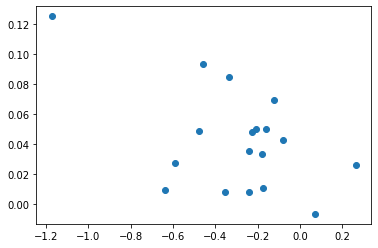

[[6.02289713e-05 1.12798679e-04]
 [1.12798679e-04 5.82143653e-04]]
Italy !!!
Italy ???


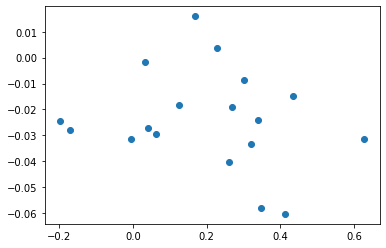

[[ 1.93842926e-05 -2.37790260e-05]
 [-2.37790260e-05  2.17009400e-04]]
India !!!
India ???


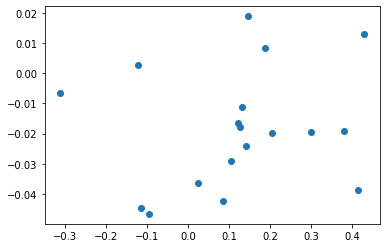

[[ 3.20258805e-05 -9.07790569e-05]
 [-9.07790569e-05  6.80854933e-04]]
Greece !!!
Greece ???
                                                    Country Name Country Code  \
Series Name                                                                     
GDP (current US$)                                    Afghanistan          AFG   
GDP (current US$)                                        Albania          ALB   
GDP (current US$)                                        Algeria          DZA   
GDP (current US$)                                 American Samoa          ASM   
GDP (current US$)                                        Andorra          AND   
...                                                          ...          ...   
NaN                                                            0            0   
NaN                                                            0            0   
NaN                                                            0            0   
Data from databa

ValueError: ignored

In [ ]:
soi_adi= compute_soi_adi(adi, country_list, product_list,country_list2, product_list2, opportunity_gain)
soi_adi_list = sorted(soi_adi.items(), key=operator.itemgetter(1))
gdp_raw=pd.read_csv(root_path+'GDP4.csv', index_col=0).fillna(0)
print(gdp_raw)
reg, growth = compute_regress(soi_adi, gdp_raw, country_list, country_list2)
# print(len(country_list))
# print(len(country_list2))
# print(len(soi_adi_list))
reg.summary()

In [ ]:
soi_adi

{'Italy': 0.22588891381856024,
 'India': -0.017839965540460856,
 'Greece': -0.034244152309331755}

categorization verified


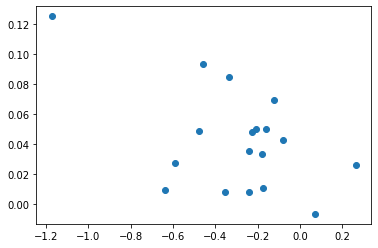

[[6.02289713e-05 1.12798679e-04]
 [1.12798679e-04 5.82143653e-04]]
Italy !!!
Italy ???


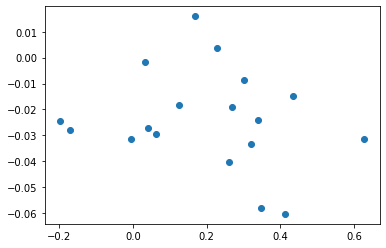

[[ 1.93842926e-05 -2.37790260e-05]
 [-2.37790260e-05  2.17009400e-04]]
India !!!
India ???


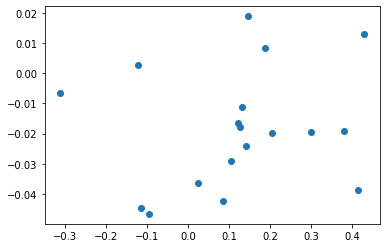

[[ 3.20258805e-05 -9.07790569e-05]
 [-9.07790569e-05  6.80854933e-04]]
Greece !!!
Greece ???


NameError: ignored

In [ ]:
soi_adi= compute_soi_adi(adi, country_list, product_list,country_list2, product_list2, opportunity_gain)
soi_adi_list = sorted(soi_adi.items(), key=operator.itemgetter(1))

#UPDATED - GDP4 needed other reworks

gdp_raw = df7.fillna(0)

#reg, growth = compute_regress(soi_adi, gdp_raw, country_list, country_list2)

# print(len(country_list))
# print(len(country_list2))
# print(len(soi_adi_list))
reg.summary()

In [ ]:
c= main_country
sorted_x = sorted(soi_adi.items(), key=lambda kv: kv[1], reverse=True)
for i in range(len(sorted_x)):
  print(i, "  ", sorted_x[i])
soi_plotter(c, adi, country_list, product_list, country_list2, product_list2, opportunity_gain)
print('SOI', soi_adi[c],'Growth', growth[c])
for i in growth.keys():
 if i=='Viet Nam':
  i='Vietnam'
  print(i, "\t", growth[i])

0    ('Italy', 0.22588891381856024)
1    ('India', -0.017839965540460856)
2    ('Greece', -0.034244152309331755)
categorization verified
ASDFASDFASDFSADFASDFASDFASDF R^2:  0.27142486006452715 ASDFASDFASDFASDF)





NameError: ignored

SOI w/ Opportunity Gain

In [ ]:
soi_oppg= compute_soi_oppgain(country_list, product_list,country_list_18, product_list_18, opportunity_gain, opportunity_gain_18)
print(sorted(soi_oppg.items(), key=operator.itemgetter(0)))
#print(np.intersect1d(country_list,country_list_18))
reg_opp= compute_regress(soi_oppg, gdp_raw, country_list, country_list_18)
reg_opp.summary()

categorization verified
[('Greece', 0.4361568129258455), ('India', 0.1941520597588291), ('Italy', 0.817644381611153)]


<ipython-input-62-7ba26f0180b2>:16: FutureWarning:

elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison



ValueError: ignored

categorization verified
[('Greece', 0.14739824125187673), ('India', -0.060220537176773226), ('Italy', -0.010977713631764141)]


<ipython-input-62-7ba26f0180b2>:16: FutureWarning:

elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison



ValueError: ignored

# End

In [ ]:
print(np.sort(list(soi_adi.keys())))
print(np.sort(country_list))
print(np.sort(country_list2))

['Greece' 'India' 'Italy']
['Greece' 'India' 'Italy']
['Albania' 'Angola' 'Argentina' 'Armenia' 'Aruba' 'Australia' 'Austria'
 'Azerbaijan' 'Bahamas' 'Bahrain' 'Barbados' 'Belarus' 'Belgium' 'Belize'
 'Benin' 'Bermuda' 'Bosnia Herzegovina' 'Botswana' 'Brazil'
 'Brunei Darussalam' 'Bulgaria' 'Burkina Faso' 'Burundi' 'Cabo Verde'
 'Cambodia' 'Canada' 'Cayman Islands' 'Central African Republic' 'Chile'
 'China' 'China, Hong Kong Special Administrative Region'
 'China, Macao Special Administrative Region' 'Colombia' 'Comoros' 'Congo'
 'Costa Rica' 'Croatia' 'Cyprus' 'Czechia' "Côte d'Ivoire"
 'Democratic Republic of the Congo' 'Denmark' 'Dominican Republic' 'EU-28'
 'Ecuador' 'Egypt' 'El Salvador' 'Estonia' 'Ethiopia' 'Fiji' 'Finland'
 'France, Monaco' 'French Polynesia' 'Gambia' 'Georgia' 'Germany' 'Greece'
 'Grenada' 'Guatemala' 'Guyana' 'Honduras' 'Hungary' 'Iceland' 'India'
 'Indonesia' 'Ireland' 'Israel' 'Italy' 'Jamaica' 'Japan' 'Jordan'
 'Kazakhstan' 'Kenya' 'Kiribati' 'Kuwait' 'Kyr